# 2023年Java大厂面试｜06：RabbitMQ与Kafka消息可靠性、集群与性能

> 学习目标：从生产者、Broker、消费者三个环节解释消息可靠性，讲清重复消费、延迟任务、积压处理、集群复制，以及Kafka日志和高性能机制。

**主要依据：** `5.2023版Java面试教程/06-消息中间件篇/PPT/06-消息中间件篇.pptx`，共46页。已读取全部文字、组合形状、表格与备注，查看26张去重图片总览，单独检查TTL/DLX、延迟插件、Kafka位移提交、副本配置和保留时间截图。第46页为空白。本笔记内嵌3张原课件配置图，并在旁边说明适用范围或问题。

**配套阅读：** 网盘`在线讲义文稿.txt`的一行链接，以及[飞书《消息中间件篇》](https://heuqqdmbyk.feishu.cn/wiki/J74owY9Wri7gApkfIDWcTQ6anle)的14组正文问答。网页标示2024年8月29日修改，正文属于课程问答，未将评论区内容作为依据。06根目录实际包含PPT、视频和在线讲义入口。视频目录共11节，已核对全部标题，**未观看或转写视频**。

“课件要点”保留原课件的问题和机制。“补充说明”“修正”解释工程条件、版本变化及示例缺陷。RabbitMQ、Kafka、Spring AMQP的默认参数和API会随版本变化，课件未提供完整运行版本清单。补充内容未逐项联网核验最新版本，使用配置前应以项目实际版本文档为准。

代码、SQL、配置和计算均为学习示例，**未编译或执行**，未安装插件、部署MQ、创建队列/Topic、发送业务消息或压测。课程里的“我们项目”、百万积压和三节点集群属于教学案例，不能直接写成个人真实经历。

### 阅读路线

- 1～8：消息模型、可靠投递、持久化、确认、重试与幂等
- 9～12：死信、TTL、延迟插件与超时订单
- 13～17：积压、惰性队列、普通/镜像/仲裁队列及监控
- 18～26：Kafka分区、发送确认、位移、重复、顺序、复制与选举
- 27～31：日志Segment、清理、页缓存、零拷贝、压缩与批量
- 32～36：综合案例、排障、面试自测、练习和来源勘误


## 1. 为什么使用MQ：收益与新增的工作

**课件第2～4页：** 常见用途包括异步通知、MySQL与Redis/ES数据同步、分布式事务中的可靠消息、削峰填谷。RabbitMQ部分围绕不丢失、重复、延迟、积压和高可用。Kafka部分还覆盖存储清理和性能。

| 用途 | 例子 | 获得什么 | 需要处理什么 |
|---|---|---|---|
| 异步处理 | 下单后发通知 | 主请求可以较早返回 | 通知失败、重复、过期、执行进度 |
| 解耦 | 订单事件由积分、统计订阅 | 生产者减少对每个下游的直接调用 | 事件字段兼容、消费者职责与隔离 |
| 削峰 | 短时大量请求进入队列 | 平滑下游处理负载 | 等待时间、容量、流控与丢弃策略 |
| 数据同步 | DB提交后更新ES | 异步维护派生数据 | 最终一致性、重试、乱序与补偿 |
| 事件日志 | Kafka供多个消费组读取 | 独立进度与一定时间内回放 | 分区设计、保留期、落后消费者 |

**补充说明：** 队列积压会把“即时处理压力”转换为“等待与存储压力”。下游持续只能处理500条/秒、上游持续产生1000条/秒，增加存储只能延后容量耗尽，不能使系统长期平衡。

RabbitMQ常用模型是：生产者发布给Exchange，Exchange按类型和绑定关系路由到Queue，消费者订阅Queue。Exchange通常承担路由职责，不能把它当成保存所有业务消息的持久日志。

Kafka常用模型是：生产者写Topic中的Partition，Broker保存有序日志，Consumer Group按各分区位移读取。两个消费组可以独立读取同一Topic。消费者提交位移不会直接删除日志。

**面试表达：** 先说明具体业务需要异步、削峰还是回放，再解释可靠性、幂等、顺序、时效与容量要求，最后说明为什么所选MQ满足这些条件。仅说“解耦、异步、削峰”不足以说明设计完成。


## 2. 不丢失、至少一次与业务只生效一次

**课件第4～9、24～29页：** 两种MQ都从生产者、Broker、消费者分析消息丢失，并用幂等处理重复消费。

**补充定义：**

| 语义 | 常见动作顺序 | 失败后可能发生什么 |
|---|---|---|
| At-most-once，至多一次 | 先认为完成，再做业务 | 中途崩溃可能漏做业务 |
| At-least-once，至少一次 | 做完业务，再确认/提交进度 | 业务已成功但确认丢失时重复执行 |
| Exactly-once，恰好一次 | 在指定事务边界内原子处理输出与进度 | 必须说明边界及外部系统是否参加事务 |

“消息不丢失”需要明确起点和终点。数据库已经提交而应用还没把事件写进MQ就崩溃，Broker持久化无法解决。消费者已经拿到消息却先ACK、后写数据库，生产者Confirm也无法解决。

~~~text
业务事务提交
事件进入可恢复的发送记录
发布并取得Broker确认
消息在Broker保存/复制
消费者提交业务事务
消费者ACK或提交安全位移
~~~

上面的每个衔接处都可能出现“结果成功，但调用方没收到成功回应”。这种不确定性使重试变得必要，也使重复可能发生。可靠投递与幂等通常需要一起设计。

**重要边界：** Kafka生产者幂等主要防止特定生产者会话重试造成的重复日志写入。Kafka事务可把Kafka输出记录和消费位移纳入同一事务。外部数据库、短信、支付不因此自动获得恰好一次语义。业务要通过数据库约束、状态机、外部幂等键或对账保证结果。

回答“不丢”时同时说清正常故障范围、存储和副本条件、重试与补偿流程。不能把某个配置概括成任何故障下都不会丢。


## 3. RabbitMQ生产者：Confirm与Return各确认什么

**课件第4～5、8页，在线问答1：** 开启生产者确认，失败时记录、重发或保存到数据库定时补偿。

| 机制 | 关注的环节 | 应用需要做什么 |
|---|---|---|
| Publisher Confirm | Broker对发布的处理结果 | 处理ACK、NACK、确认超时和连接中断 |
| Publisher Return | 消息未能按路由找到队列 | 开启mandatory并处理退回，检查绑定与routing key |
| Consumer ACK | 已投递消息的消费结果 | 等实际业务提交后确认 |

**修正：** Confirm的ACK不能简单理解为“消费者处理成功”。对于未能路由的消息，Broker仍可能发送Confirm ACK，同时因mandatory退回消息。因此生产者必须关联同一消息的Return与Confirm结果，不能仅看Confirm就把业务发送记录永久标成成功。

学习用Spring Boot配置片段，具体属性路径与依赖版本要核对：

~~~yaml
spring:
  rabbitmq:
    publisher-confirm-type: correlated
    publisher-returns: true
    template:
      mandatory: true
~~~

发送时给消息一个稳定的业务`event_id`，用CorrelationData等机制关联回调。一次重试可以有新的发送尝试编号，但业务事件ID应保持稳定，便于消费者识别重复。

| 观测到的结果 | 判断 | 后续处理 |
|---|---|---|
| 无Return并获得符合队列保证条件的Confirm ACK | 此次发布成功 | 更新发送记录状态 |
| Return | 路由失败 | 修复队列/绑定或发布参数，再按规则重试 |
| Confirm NACK | Broker拒绝/未成功接管 | 持久记录失败并有界重试 |
| 超时、连接断开 | 发布结果未知 | 使用同一event_id重发，接受重复可能 |

**补充说明：** Exchange不存在等Channel级错误也需处理。Return不是所有发布异常的统一入口。不要在回调中无界立即重发，否则路由配置错误会持续放大流量。Confirm用于判定Broker接管范围，业务事务与事件发布的衔接另见第4节。


## 4. 可靠发布补充：本地消息表与Outbox

**课件第5页：** 提到保存失败消息后定时重发。以下把它补充为一个可恢复的业务流程，与第05篇的可靠消息事务衔接。

~~~text
同一个数据库本地事务：
  更新业务数据
  插入outbox(event_id, aggregate_id, version, payload, status=NEW)
事务提交

独立发布任务读取待发送事件
按event_id发布，等待确认并关联Return
确认成功后更新为SENT
失败/未知时记录原因、次数与下次重试时间
~~~

**为什么要在同一事务里写Outbox？** 如果先提交订单、再另开事务插入待发送消息，两步之间崩溃仍会漏事件。同一数据库事务保证“业务变更和发送意图一起成功或一起回滚”。发布到MQ仍是后续步骤，依靠扫描/CDC、确认和重试最终完成。

**为什么仍会重复？** MQ已经接收消息，应用尚未将Outbox标成SENT就崩溃，恢复后会重发。这个窗口通过稳定事件ID和消费幂等处理。

发送记录至少保留：事件ID、业务对象、事件类型、版本、载荷或可重建载荷的引用、状态、尝试次数、重试时间、最后错误、创建时间。多个发布实例需要抢占规则、租约或分片，避免无控制重复扫描。失败记录应可查询、告警、修复和重放。

**状态设计补充：** NEW、SENDING、SENT、RETRY、DEAD等只是示例。SENDING实例崩溃后必须能恢复，不能永久卡住。超过自动重试上限不等于删除业务意图，应进入可审计的失败处理流程。

课程说成功后“删除表中数据”。实践中可先标记成功，保留一定审计期再归档清理。数据量与合规要求决定保留策略。无论选哪种，都要先确认状态更新与发布结果关联正确。

**面试追问：** “本地消息表是否让跨系统立即强一致？”它保证本地业务与发送意图的原子性，跨系统通常仍是最终一致。重试、幂等、监控与对账决定是否能真正收敛。


## 5. RabbitMQ持久化：对象定义、消息数据与副本

**课件第6页，在线问答1：** 对Exchange、Queue和Message启用持久化。

~~~java
@Bean
public DirectExchange simpleExchange() {
    return new DirectExchange("simple.direct", true, false);
}

@Bean
public Queue simpleQueue() {
    return QueueBuilder.durable("simple.queue").build();
}

Message message = MessageBuilder
    .withBody(body.getBytes(StandardCharsets.UTF_8))
    .setDeliveryMode(MessageDeliveryMode.PERSISTENT)
    .build();
~~~

| 配置 | 保存什么 | 不能单独承担什么 |
|---|---|---|
| Exchange durable | 交换机定义在重启后恢复 | 不直接保存Queue中的业务消息 |
| Queue durable | 队列定义及对应恢复条件 | 不把所有非持久消息变成持久消息 |
| Message persistent | 请求对消息持久保存 | 还需相应队列、确认与存储条件 |
| Quorum等复制队列 | 跨节点复制与队列容错 | 不能代替生产者确认与消费事务 |

**修正：** “MQ默认内存存储”“持久化后一定不丢”都过于绝对。队列类型和RabbitMQ版本影响内存/磁盘策略。对经典队列，持久队列与持久消息通常要配合，生产者还应等待Confirm。磁盘损坏、所有副本故障、误删、保留/过期策略和错误确认属于不同风险。

Spring AMQP的具体消息构造与转换方式会影响属性，不能因某个默认值就省略检查。可靠性要求明确时，直接验证实际发出的delivery mode、队列类型与声明参数。

**队列声明注意：** 已存在队列的类型或参数与本次声明不兼容，可能触发声明失败，而不是自动改成新配置。生产环境迁移队列应有新队列、消费者切换、消息迁移及回退计划，不能随手删队列重建。

持久化回答要连成一条链：发布确认、持久队列和消息、满足容错条件的副本、业务提交后ACK，以及监控/恢复。只展示三个`true`无法证明整条链可靠。


## 6. Spring AMQP的AUTO、MANUAL与NONE

**课件第7～8页，在线问答1～2：** MANUAL由业务代码确认，AUTO由Spring根据监听器执行结果确认，NONE不等待处理结果。

| 模式 | 谁决定确认 | 业务代码的要求 |
|---|---|---|
| AUTO | Spring监听容器 | 监听器返回成功必须代表实际业务已经成功 |
| MANUAL | 监听器显式调用Channel API | 管理ACK/NACK、异常、提交时点和重复 |
| NONE | 投递时即视为完成 | 中途处理失败可能无法由Broker重投 |

**容易混淆的边界：** Spring的`AcknowledgeMode.AUTO`由容器在监听器处理后确认，并不等于AMQP协议里的`autoAck=true`。Spring的NONE更接近不等待业务处理确认的模型。不能因为名称里有“自动”就把AUTO解释成一投递就删除。

概念性手动确认示例，省略导包、容器配置和分类异常：

~~~java
@RabbitListener(queues = "order.events")
public void consume(Message message, Channel channel) throws IOException {
    long tag = message.getMessageProperties().getDeliveryTag();
    try {
        // 调用独立Spring代理Bean，其本地事务在方法返回前完成提交。
        orderEventService.applyIdempotently(message);
    } catch (TransientBusinessException failure) {
        // 转入有界重试或故障流程，不在此无限requeue。
        channel.basicNack(tag, false, false);
        return;
    }
    channel.basicAck(tag, false);
}
~~~

此片段假设失败队列已经正确配置DLX。`requeue=false`且没有合适的死信配置时，拒绝可能导致消息丢弃。异常分类、未知异常、重试次数、死信转发可靠性和ACK失败恢复需由完整工程处理。

**时点陷阱：** 若在当前监听器方法上声明`@Transactional`，方法体内发送ACK后，事务代理可能尚未提交。业务提交失败时消息已经确认。需要确保ACK发生在真实事务提交之后，例如调用独立事务服务后确认，或使用经过核对的容器事务集成。

**线程陷阱：** 监听器把任务交给线程池就正常返回，AUTO可能在任务完成前确认。delivery tag属于对应Channel，同一Channel的ACK、批量ACK与并发调用需要遵守客户端约束。`multiple=true`会确认较早的多个投递，不能用于跨越仍未完成的业务。


## 7. RabbitMQ重试：短暂故障、毒消息与失败归档

**课件第7～8页：** Spring本地Retry达到次数后，将消息投递到异常Exchange，由人工处理。在线问答以3次重试为例。

示意配置，适用于课程常见simple监听容器，实际配置项须核对版本：

~~~yaml
spring:
  rabbitmq:
    listener:
      simple:
        acknowledge-mode: auto
        retry:
          enabled: true
          initial-interval: 1000
          multiplier: 2
          max-interval: 10000
          max-attempts: 3
~~~

**补充说明：** `max-attempts`通常表示包括首次执行在内的总尝试次数，不能把3直接说成首次之外再重试3次。启用本地Retry并不会自动生成异常Exchange、Queue或Recoverer。需要配置相应失败恢复器，如版本支持的`RepublishMessageRecoverer`或具有发布确认保障的对应实现。

| 失败类型 | 例子 | 处理倾向 |
|---|---|---|
| 短暂故障 | 网络抖动、短时数据库不可用 | 少量本地重试，退避并限制时间 |
| 需要较长等待 | 第三方持续故障 | 延迟重试，释放业务线程，限制总次数 |
| 数据/代码问题 | 非法字段、无法反序列化 | 快速归档死信，修复后重放 |
| 结果未知 | DB或外部调用成功但响应断开 | 按业务ID查询状态，幂等重试或对账 |

本地重试通常仍占用监听处理资源。大量慢重试会压低吞吐并增加unacked，不能在下游宕机时让所有消费线程同时疯狂重试。

**确认失败归档的责任：** 如果把失败消息重新发布到异常队列后原消息就确认，必须保证重新发布确实成功。仅在内存记录失败日志或发起异步发布就视为完成，会产生新丢失窗口。恢复器行为、Confirm、事务条件及队列类型需一起核对。

死信需要有事件ID、失败原因、尝试次数、时间、原路由及可定位的业务信息。人工处理也应有负责人、时限、重放权限和审计。修复后使用原event_id重放，让幂等机制继续生效。


## 8. 重复消费：稳定业务键与持久幂等

**课件第9页，在线问答2～3：** 网络抖动、消费者崩溃会造成重复投递。课程提出业务唯一标识、数据库校验、Redis锁或数据库锁。

~~~text
消费者收到事件E
数据库事务提交成功
ACK尚未到Broker，连接断开
Broker重投E
消费者再次收到E
~~~

**修正：** “先查是否存在，不存在再插入”若没有约束与事务，会在并发下同时通过。分布式锁控制同一时刻的竞争，锁释放后再次投递仍可能再次执行。持久业务状态或唯一约束承担长期去重职责。

学习用Inbox设计：

~~~sql
CREATE TABLE consumed_event (
    consumer_name VARCHAR(64) NOT NULL,
    event_id VARCHAR(64) NOT NULL,
    payload_hash CHAR(64) NOT NULL,
    completed_at DATETIME NOT NULL,
    PRIMARY KEY (consumer_name, event_id)
);
~~~

~~~text
同一个数据库事务：
  尝试插入(consumer_name, event_id, payload_hash)
  应用业务变更
提交事务后ACK/提交位移

若插入遇到唯一键冲突：
  回滚当前事务
  核对已提交记录及payload_hash
  确认同一事件已成功处理后，视为幂等成功
~~~

只有Inbox与业务写入同一事务成功，记录才表示完成。不能先独立提交“已消费”，随后业务失败。若使用PROCESSING状态单独抢占，需要超时恢复、完成状态与重入协议，复杂度更高。

**去重键如何选择？** 支付事件用稳定event_id或支付业务操作ID。订单有创建、支付、退款多个合法事件，仅用order_id去重会误屏蔽后续操作。多个独立消费者可能都要处理同一event_id，因此示例主键包含consumer_name。

**状态机补充：** 对“待支付变已支付”可用带前置状态/版本的条件更新，并核对影响行数。对余额累加、积分增加，重复一次就会多算，宜使用交易流水唯一键与余额更新同事务。Redis缓存去重需考虑过期、淘汰、故障与数据库提交之间的窗口。

外部短信或支付副作用不能和本地Inbox直接组成普通数据库事务。优先使用第三方幂等键/查询接口，必要时增加Outbox与对账。持久幂等记录的保留期还应覆盖消息保留、补偿与人工重放周期。


## 9. 死信与DLX：消息如何进入故障队列

**课件第10～11页，在线问答4：** 消息可能因拒绝、过期或队列容量达到限制成为死信。原队列配置死信Exchange后，Broker将符合条件的消息重新发布到该Exchange。

| 触发条件 | 课程例子 | 补充边界 |
|---|---|---|
| 消费者拒绝 | basic.reject/basic.nack且requeue=false | 有DLX才按死信路径处理，普通重入队不属于此路径 |
| 消息TTL到期 | 超时仍未消费 | 受过期检查与队列实现影响 |
| 长度上限 | 队列积压达到上限 | 是丢头、拒绝发布还是死信，取决于overflow策略/类型 |
| Quorum投递限制 | 多次失败超过delivery limit | 新版本/队列类型特性，参数与默认值需核对 |

**修正：** DLX是普通Exchange承担“死信转发”的职责，并不是新的独立Exchange类型。它仍可以是direct、topic等。延迟插件也不能称为“死信插件”。

~~~text
publisher发布到normal.exchange
按routing key进入normal.queue
normal.queue中的消息符合死信条件
重新发布到dl.exchange
由DLX绑定与死信routing key决定进入哪条队列
dl.queue的消费者处理/归档
~~~

原队列的常见参数是`x-dead-letter-exchange`、`x-dead-letter-routing-key`。若未覆盖routing key，路由行为需按实现与原消息路由属性分析。目标Exchange、绑定和Queue必须存在且权限正确，否则死信链路也可能失效。

**补充说明：** 死信重发布不是天然的跨队列可靠事务。经典队列与Quorum的死信转发能力和确认选项不同，某些组合存在转发时目标不可用导致丢失的窗口。严格要求下应核对队列类型、dead-letter策略及版本支持。

Broker附加的`x-death`等头可帮助追踪死信原因、队列和次数，不能默认把它等同于所有应用重试次数。应用重新创建消息、普通requeue、本地Retry都可能不符合相同计数规则。

故障队列与延迟触发队列职责不同：前者保存失败，后者承担业务时间触发。设计时明确哪个消费者处理哪条队列，避免死信反复路由回原队列形成循环。


## 10. TTL加DLX：课程里的延迟队列

**课件第10～12页：** 在没有消费者的等待队列中设置TTL，过期后经DLX进入实际业务队列。

课程TTL/DLX配置图，单位为毫秒：

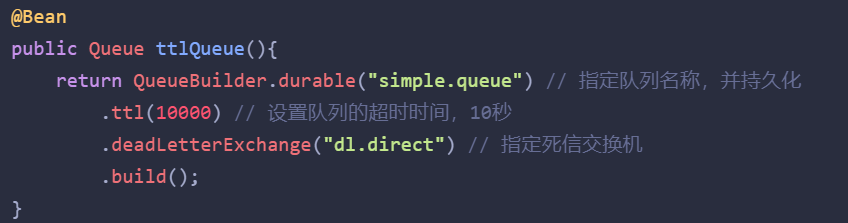

按课程思路整理的声明片段：

~~~java
@Bean
public Queue waitQueue() {
    return QueueBuilder.durable("ttl.queue")
        .ttl(10000)
        .deadLetterExchange("dl.direct")
        .deadLetterRoutingKey("dl")
        .build();
}

@Bean
public DirectExchange waitExchange() {
    return new DirectExchange("ttl.direct", true, false);
}

@Bean
public DirectExchange actualExchange() {
    return new DirectExchange("dl.direct", true, false);
}
~~~

完整工程还需声明等待队列绑定、实际业务队列及其DLX绑定。等待队列通常不放业务消费者，业务消费者订阅实际处理队列。否则等待中的消息可能直接被消费，失去延迟效果。

消息级TTL片段：

~~~java
rabbitTemplate.convertAndSend("ttl.direct", "ttl", event, message -> {
    message.getMessageProperties().setExpiration("5000");
    return message;
});
~~~

队列TTL是队列内消息的存活上限，消息expiration是该消息的存活时间。当两者都设置时通常取较短者。课程示例队列10000ms、消息5000ms，应按5000ms上限理解。

**补充队头阻塞：** 在同一FIFO等待队列混合很长与很短的消息TTL时，后面的短TTL消息即使过期，也可能等待前面的消息移除后才进入死信处理。不同队列类型和版本实现有差异，因此不能把消息expiration当成任意延迟下都精确触发的定时器。

**补充区分：** `x-message-ttl`控制消息存活，`x-expires`控制队列在满足未使用条件后何时过期，两者用途不同。TTL也通常不用于让已投递、正在处理的消息在超时瞬间自动中断业务。

延迟任务要求误差范围、持久性、最大延迟与数量规模。可选固定TTL多级队列、延迟插件或专门调度系统，仍需业务截止时间检查和补偿扫描。


## 11. 延迟插件：delayed属性与x-delay

**课件第13～15页：** 使用RabbitMQ delayed-message-exchange插件，声明Exchange时设置delayed，发送时设置`x-delay`。

Spring AMQP监听声明示例，仅用于理解配置位置：

~~~java
@RabbitListener(bindings = @QueueBinding(
    value = @Queue(value = "delay.queue", durable = "true"),
    exchange = @Exchange(value = "delay.direct", type = "direct", delayed = "true"),
    key = "delay"
))
public void listen(OrderTimeoutEvent event) {
    timeoutService.checkAndCloseIfExpired(event);
}

rabbitTemplate.convertAndSend("delay.direct", "delay", event, message -> {
    message.getMessageProperties().setHeader("x-delay", 10000);
    return message;
});
~~~

**机制修正：** 插件在Broker侧使用`x-delayed-message`类型，并通过`x-delayed-type`指定延迟结束后的路由行为。Spring中的`type="direct", delayed="true"`是声明封装，不能据此说Broker端仍只是一个未安装插件的普通direct Exchange。只有客户端配置delayed而Broker未启用兼容插件，不能完成延迟功能。

`x-delay=10000`在课程示例表示10000ms后进行延迟路由。插件实际的延迟消息存储、重启恢复、最大延迟、复制和Confirm/Return语义必须查对应插件版本文档。不能把延迟插件自动当成与Quorum队列等价的复制保证，也不能把普通mandatory的预期完全套到未来才发生的路由。

**工程补充：** 延迟消息里保留event_id、业务ID、due_at和版本。收到后检查当前数据库时间与业务状态，允许重复与晚到，并通过补偿扫描发现超过截止时间仍未完成的任务。

**与TTL/DLX的选择：** TTL/DLX适合可接受误差的固定档位延迟。插件简化不同延迟值的路由，但依赖插件兼容性与运维支持。大量长时间任务、需要取消或改期、强审计的场景应评估数据库任务表、调度器等方案。

此处只解释原课件配置，未安装或运行插件。


## 12. 超时关单：延迟触发后的业务正确性

**课件第10、15页：** 超时订单、限时优惠和定时发布是延迟队列应用。以下补充以订单为例说明完整流程。

~~~text
创建订单事务：
  保存订单(PENDING_PAYMENT, expire_at, version)
  同事务写超时检查Outbox事件

收到超时事件：
  核对订单ID、事件身份与数据库当前状态
  当前时间未到expire_at则按规则再调度
  已支付/已关闭则幂等返回
  在允许状态下提交关单事务
  事务提交后ACK
~~~

学习用条件更新：

~~~sql
UPDATE orders
SET status = 'CLOSED', version = version + 1
WHERE id = :order_id
  AND status = 'PENDING_PAYMENT'
  AND expire_at <= CURRENT_TIMESTAMP
  AND version = :expected_version;
~~~

影响行数为0需要查询当前状态，判断是已经支付、已经关闭、版本变化还是尚未到期。不能统一当成数据库失败并永久重试。

**支付竞争：** 支付回调和关单同时到达，必须由数据库状态迁移约束、版本或锁序列化竞争。还需定义第三方支付已经成功但本地关单先提交时的处理方式，例如查询支付状态、退款或人工对账。MQ的时间触发无法自行裁决跨系统支付事实。

**取消与改期：** 若订单期限被延长，旧事件仍可能到达。以当前expire_at/业务版本判断旧事件是否仍有效。通过数据库状态判断通常比试图从Broker精准撤回某条延迟消息更容易保持正确性。

**最终兜底：** 定时扫描已经过期仍待支付的订单，按同一个幂等关单服务处理，防止发布漏项、延迟异常或消费故障留下永久订单。定期对账涵盖本地订单与外部支付状态。

面试时应同时说明触发方式、重复处理、支付竞争和补偿。仅说“TTL到了就关闭订单”会遗漏实际业务风险。


## 13. 百万消息积压：定位瓶颈与估算恢复时间

**课件第16～18页，在线问答5：** 提高消费速度、增加消费者、增加队列容量。课程还提到线程池和惰性队列。

**先区分指标：** Ready是等待投递的消息，Unacked是已经投递但未确认的消息。Ready持续增长通常说明消费能力不足或消费中断。Unacked大可能是慢业务、线程卡住、prefetch过大或ACK路径异常。

排查顺序：

1. 看积压增长速度、最老消息年龄和业务时效，判断是否已超SLA。
2. 检查消费者是否在线、失败率/重试次数、处理耗时及线程池/连接池。
3. 检查数据库锁、慢SQL、第三方限流、磁盘、网络和Broker资源告警。
4. 确认扩消费者会增加真实吞吐，并且下游能承受新增并发。
5. 保留幂等、顺序和安全确认规则，逐步扩容并观测回落。

**补充计算：** 设当前积压B，持续生产速率λ，总成功消费速率μ。当μ>λ时，理想恢复时间约为`B/(μ-λ)`。例如B=100万，λ=2000条/秒，μ=5000条/秒，理想清空时间约333秒。还要加上启动、重试、热点与资源竞争影响。若μ≤λ，积压无法持续清空。

| 措施 | 适用前提 | 常见限制 |
|---|---|---|
| 增加消费者 | 任务可并行、队列允许竞争消费 | 顺序要求、数据库瓶颈、单队列能力 |
| 优化单条消费 | 发现慢SQL/同步外调等 | 需要保留事务和幂等正确性 |
| 批量处理 | 业务允许批量与故障隔离 | 大事务、部分成功与确认复杂度 |
| 分队列/分片 | 业务key可合理分片 | 路由改造、热点、跨片顺序 |
| 有界线程池 | 安全管理Channel、ACK、在途任务 | 提前ACK、无界堆积、并发顺序 |
| 增加存储 | 短时高峰需缓冲 | 只增加容量，不消除长期吞吐缺口 |
| 上游流控 | 下游不能继续扩容 | 对用户体验与业务优先级有影响 |

**积压应急补充：** 临时消费程序仍需做完整业务处理、幂等与成功确认。不能为清空数字而直接ACK或转存后假定任务已完成。过时通知、价格事件等是否可丢弃，要由业务规则明确授权，不能一概删除。


## 14. 惰性队列：旧课件配置与版本变化

**课件第17～18页：** Lazy Queue尽量把消息放在磁盘，需要消费时再读取，以减少大量积压占用内存。课程给出的旧式声明为：

~~~java
// 历史课程示例，不应直接套用于所有RabbitMQ版本。
QueueBuilder.durable("lazy.queue").lazy().build();
// 对应旧参数：x-queue-mode = lazy
~~~

**补充版本说明：** RabbitMQ较新经典队列已经改变消息内存/磁盘管理策略。从3.12起，旧lazy模式不再按旧语义作为独立模式使用，`x-queue-mode=lazy`不能继续作为通用调优建议。项目需要核对Broker、客户端版本和队列类型。此说明是版本补充，未逐项核验当前最新发行版。

Lazy讨论的核心是**内存与磁盘使用策略**。它不能提高业务处理能力，也不等于跨节点复制，更不能代替publisher confirm、消费ACK和持久幂等。

大量磁盘缓冲仍受磁盘容量、IOPS、吞吐、页缓存、文件系统和保留策略约束。消费者追赶旧消息可能读冷数据，增加磁盘读压力。需要设置磁盘空间告警、容量预测和排队时效指标。

**面试回答：** 先说明课程版本中惰性队列适合大量积压、以磁盘换内存压力，再补充新版本经典队列变化。解释它承担容量与资源管理，消费速度问题另用扩容、优化或上游流控解决。


## 15. RabbitMQ普通集群与历史镜像队列

**课件第19～21、23页，在线问答6：** 普通集群共享部分元数据。镜像队列复制队列消息，主节点故障后镜像节点可接替。

| 项目 | 普通集群中的非副本经典队列 | 历史经典镜像队列 |
|---|---|---|
| 元数据 | 节点共享必要的集群定义 | 共享并按策略配置队列副本 |
| 消息 | 队列由其所在节点保存 | 在指定镜像节点复制 |
| 客户端访问 | 可连接其他集群节点，内部转发 | 通常由队列主节点处理并复制 |
| 节点故障 | 该节点上的队列可能不可用 | 满足条件的副本可提升为主 |
| 可靠性重点 | 单节点存储恢复条件 | 副本同步状态、确认与切主策略 |

**修正：** “普通集群队列所在节点宕机就丢失所有消息”不准确。暂时不可用与永久丢失不同。若持久化数据仍在、原节点恢复，可能恢复消息。若磁盘永久损坏且没有副本/其他恢复措施，才会造成不可恢复损失。

多个节点存在并不代表每条队列都自动具备消息副本。集群、队列类型、队列副本策略和副本成员需要分别核对。负载均衡连接入口也不能让一个无副本队列在节点故障后凭空恢复。

**历史镜像风险：** 未完成同步的副本切主可能影响数据安全。镜像副本越多，复制开销也越大。课程中“三节点镜像集群”是案例口述，不能写成自己的生产环境。

**补充版本说明：** 经典镜像队列已在RabbitMQ 4.0移除。学习旧课件时理解其主从思想，新项目优先评估Quorum Queue等当前版本支持的队列类型。已有系统升级需规划迁移，不能只升级Broker而保留已移除功能的假设。

真正的高可用还包括客户端重连、发布确认恢复、消费者重新订阅、故障域分散、资源容量与可观测性。队列切主期间的未知结果仍需幂等与重试处理。


## 16. 仲裁队列Quorum：Raft与多数派

**课件第22～23页，在线问答7：** Quorum Queue从RabbitMQ 3.8引入，用于替代历史镜像队列，基于Raft进行复制。

~~~java
@Bean
public Queue quorumQueue() {
    return QueueBuilder.durable("quorum.queue")
        .quorum()
        .build();
}
~~~

**补充说明：** 这段声明指定队列类型，不能单独保证三副本已经部署、成员跨故障域分散或多数派永远在线。还要检查实际队列成员、节点状态、存储、资源限制及客户端确认策略。

Raft复制组包括leader与followers，多数派参与已提交日志的安全性和领导者选举。复制组有N个成员时，多数派为`floor(N/2)+1`。

| 成员数 | 多数派 | 在常见多数派条件下可容忍同时失去的成员数 |
|---|---:|---:|
| 3 | 2 | 1 |
| 5 | 3 | 2 |

这些是成员可用性条件示意，还需满足网络、磁盘和实际协议状态。三个进程若都放同一台主机，主机故障会一起失去，无法获得主机层面的容错。

**网络分区：** 通常只有能满足多数派条件的一侧继续进行需要提交的操作。少数派不能为了可用而任意接受不受约束写入。恢复后按协议追赶，不能仅凭“强一致”断言业务永远不停顿。

**发布确认边界：** Quorum队列的Confirm需要结合其复制提交条件分析。应用仍需等待Confirm、处理未知结果，并在消费端事务提交后ACK。Quorum解决队列复制层面的可靠性，不能修复上游事务没写Outbox或消费者提前确认。

副本增加会增加复制、磁盘、网络与恢复成本。根据允许故障、故障域和负载规划成员数，核对成员扩缩、磁盘损坏与集群恢复的具体版本流程。


## 17. RabbitMQ完整回答与监控要点

**依据课件第8、18、23页整理：** 回答“不丢失”应覆盖发布、保存、处理、补偿与运维，并明确发生故障时的结果未知窗口。

可复述的机制回答：

> 我会在生产者开启Confirm，并用mandatory和Return检查路由失败。业务提交与事件发送意图可以通过Outbox衔接，失败或未知结果使用稳定事件ID有界重试。Broker侧使用合适的持久队列、持久消息及满足故障条件的副本。消费者实际业务事务提交后再确认，失败分类重试，超限进入可审计的失败流程。由于确认可能丢失，消费端还要有持久幂等与对账。

根据真实项目替换“可以”“会”及技术选型，不能把这段机制回答伪装成没有做过的项目经历。

| 监控内容 | 发现什么问题 |
|---|---|
| 发布成功率、NACK、Return、确认延迟 | Broker压力、路由异常、连接问题 |
| Outbox未发送数量与最老记录年龄 | 发布任务停滞、补偿长期失败 |
| Ready、Unacked、消费吞吐 | 积压、慢消费、提前投递过多 |
| 处理失败率、重试率、死信数量与年龄 | 毒消息、下游故障、人工处理滞后 |
| 磁盘、内存告警、连接数、Channel数 | 资源耗尽与流控 |
| 队列副本/成员状态、网络与恢复进度 | 高可用条件是否满足 |
| 业务成功率、最终一致性延迟 | 队列指标正常但业务未正确完成 |

**prefetch补充：** 它限制消费者/Channel一定范围内未确认的投递量，具体作用域受客户端与Broker配置影响。太小可能限制吞吐，太大可能导致消费者负载不均、Unacked过多和较慢故障恢复。基于消息大小、处理时间与并发能力调整。

调整并发与prefetch时同时观察数据库连接池、事务耗时和内存，避免只看MQ吞吐。可靠性配置、速度配置和业务正确性需要一起验证。


## 18. Kafka基础模型：Topic、Partition、Offset与消费组

**课件第24、27～28、33～35页：** Broker组成集群，Topic划分为多个Partition，Partition可以有多个副本。Consumer Group分配分区给消费者。

| 名称 | 作用 | 容易混淆的点 |
|---|---|---|
| Broker | Kafka服务节点 | 多Broker不代表每个分区都有多个副本 |
| Topic | 消息主题 | 一个Topic可有多个独立有序分区 |
| Partition | 分区日志 | 顺序与位移以分区为范围 |
| Offset | 分区内记录位置 | 不是跨所有Topic的全局消息ID |
| Replica | 分区副本 | 副本数与分区数是两个参数 |
| Consumer Group | 协同消费的一组消费者 | 不同组有独立进度 |

**课程所用传统消费组模型：** 在稳定分配状态下，同一分区由同组一个消费者拥有，一个消费者可拥有多个分区。若Topic有3个分区，消费组有5个消费者，通常最多3个消费者拿到该Topic的分区，其他消费者空闲。扩消费者不能突破该Topic分区数量带来的组内并行限制。

~~~text
Topic orders有P0、P1、P2
Group settlement：C1读P0/P1，C2读P2
Group analytics：D1读P0，D2读P1，D3读P2
两个组独立提交各自位移
~~~

消费者加入、退出、订阅或分区变化可能触发Rebalance，重新分配分区。原消费者需要停止处理被撤销分区，提交允许提交的安全位置，防止旧所有者继续写业务结果或提交不属于自己的进度。

**补充说明：** 分区所有权属于消费者，并不意味着其内部线程只会串行处理业务。把记录无序投到线程池仍可能破坏完成顺序。KafkaConsumer通常不是线程安全的，应由单个所有者线程调用poll、seek、commit等接口，其他线程的结果通过安全队列返回。

本篇讨论课程传统Consumer Group模式。Kafka新版本可能引入不同消费协议或模型，不能将所有版本/模型概括成同一行为。


## 19. Kafka生产者：同步等待、异步回调与重试

**课件第25、29页，在线问答8：** 展示`send(record).get()`、异步Callback和`retries=10`。

~~~java
// 同步等待此发送结果，阻塞调用线程。
RecordMetadata result = producer.send(record).get();

// 异步获得结果。这里只展示处理分支，不是完整可靠发布工程。
producer.send(record, (metadata, error) -> {
    if (error != null) {
        failureStore.record(eventId, error);
        return;
    }
    sentStore.record(eventId, metadata.topic(), metadata.partition(), metadata.offset());
});
~~~

**原代码修正：** 课件回调在`e != null`时仅打印日志，随后继续调用`recordMetadata.offset()`等。发送失败时metadata可能为null，应在失败分支返回或使用互斥分支。打印日志不能代替可恢复的失败记录与重发。

**同步与异步的边界：** 两者区别是等待结果的方式。异步本身不提供防丢保证，同步也不会自动解决数据库与Kafka的原子提交。异步提高并发使用效率，但必须处理回调、资源关闭、应用崩溃和持久发送意图。同步逐条等待可能降低批量效率。

学习用配置片段：

~~~java
properties.put(ProducerConfig.ACKS_CONFIG, "all");
properties.put(ProducerConfig.ENABLE_IDEMPOTENCE_CONFIG, "true");
// 课件的重试示例，不是所有场景的推荐固定值。
properties.put(ProducerConfig.RETRIES_CONFIG, 10);
~~~

**补充参数关系：** `delivery.timeout.ms`、`request.timeout.ms`、`linger.ms`、`retries`、`retry.backoff.ms`共同限制等待与重试。重试次数大不代表无限等到成功，达到总体交付超时仍可能失败。`max.block.ms`约束某些调用等待缓冲区/元数据的时间，与Broker确认等待不是同一概念。

幂等生产者对acks、retries、`max.in.flight.requests.per.connection`等有兼容条件，常见现代客户端要求acks=all、重试可用且in-flight不超过受支持上限。默认值与冲突处理随版本变化，应核对项目客户端文档。

消息过大、鉴权失败、序列化错误和错误Topic配置不能靠立即重试解决。结果未知时保持event_id不变，消费者也应幂等。应用自己在新的生产者实例中再次发送同一业务事件，不会仅靠生产者幂等自动识别为重复业务。


## 20. Kafka的acks：结合副本数与最小ISR理解

**课件第26、29、36页：** acks有0、1、all三个主要选择，课件示例副本数3、`min.insync.replicas=2`。

| acks | 生产者等待什么 | 主要风险/限制 |
|---|---|---|
| 0 | 不等待Broker的发布确认 | 发送错误难以可靠感知，数据可能未写入 |
| 1 | leader接受并写入本地日志后响应 | leader未复制就故障，已确认记录仍可能丢失 |
| all / -1 | 按协议等待ISR复制确认条件 | 必须有足够副本与合理最小ISR |

**修正：** acks=all等待的是ISR中的复制确认条件，不是所有配置副本无条件都收到。若配置3副本但只有leader在ISR，最小ISR又是1，all仍可能退化到单个有效副本的确认条件。课件把acks=1写成默认值，较新客户端默认值已经变化，面试不要背成所有版本默认1。

示例需要同时配置Topic/创建参数与producer，而不是只在一处写完：

~~~text
Topic副本数：replication.factor = 3
Topic/对应Broker有效配置：min.insync.replicas = 2
Producer：acks = all
Producer：enable.idempotence = true（并核对兼容参数）
~~~

| 三副本示例的当前ISR | min ISR=2、acks=all下的结果 |
|---|---|
| A、B、C | 可按复制确认条件写入 |
| A、B | 仍满足最小ISR，确认依赖当前ISR |
| A | 不满足最小ISR，写入失败/拒绝，不应假定成功 |

某些错误在写入后复制等待过程中出现，生产者可能得到失败或未知结果，但记录已经存在。重试与生产者/业务幂等仍有必要。

**补充磁盘边界：** acks与复制条件不应直接解释成所有副本物理介质已经执行同样的同步落盘操作。Kafka依靠日志、页缓存、复制、恢复等机制权衡性能与可靠性。多副本同时丢失、错误运维或故障域集中仍可能超出容错能力。

副本因网络或处理落后退出ISR后，应告警并查原因。不要为了“恢复写入成功率”随意降低min ISR，而不评估业务允许的数据丢失范围。


## 21. 消费位移：读取位置与提交位置

**课件第27～29页，在线问答8～9：** 自动提交可能在崩溃/Rebalance时导致重复或漏处理，建议关闭自动提交并由应用控制。

**补充定义：** Consumer当前position表示下一条读取的位置。Committed offset表示该消费组恢复后下一条要读取的位置。二者都以分区为范围，但不等于业务真实完成位置。

例子：P0本次poll返回offset100、101、102，消费者读取position可能已经到103。

| 业务进度 | 安全提交位置 | 原因 |
|---|---:|---|
| 三条都尚未处理 | 100 | 下次应从100继续 |
| 100成功，101失败 | 101 | 101和之后尚不能跨过 |
| 100、101成功，102尚未处理 | 102 | 下一条需要处理102 |
| 三条都提交业务事务 | 103 | 下一条需要处理103 |

因此“提交已经成功的offset”通常意味着提交**成功记录offset+1**。分区内并发时还必须保证提交到连续已完成的前缀，不能取任何已完成记录中的最大offset+1。

~~~java
properties.put(ConsumerConfig.ENABLE_AUTO_COMMIT_CONFIG, "false");
// records的业务真正完成后，按分区提交安全的next offset。
consumer.commitSync(safeOffsets);
~~~

**自动提交补充：** 课程常见默认`auto.commit.interval.ms=5000`，实际以客户端版本和配置为准。自动提交由消费者相关调用流程触发，不应想象成完全独立地了解业务是否完成的后台事务。若poll后业务异步进行，后续提交可能跨过未成功记录。

**两个崩溃窗口：** 先提交位移后写业务，崩溃后可能跳过未完成业务。先提交业务后提交位移，崩溃后可能重复，但有幂等可安全重做。至少一次处理通常采用后者。

手动提交只提供控制权。如果应用提交的是poll后的读取position，仍可能漏处理。还需注意`max.poll.interval.ms`、批量大小与处理耗时，超过允许间隔可能导致成员失去分区并提交失败。


## 22. 同步、异步提交与课件finally示例修正

**课件第28～29页：** 展示同步、异步以及日常异步、退出时同步的组合。以下原图保留课程写法，**无条件提交全部读取位置的问题需按本文修正**。

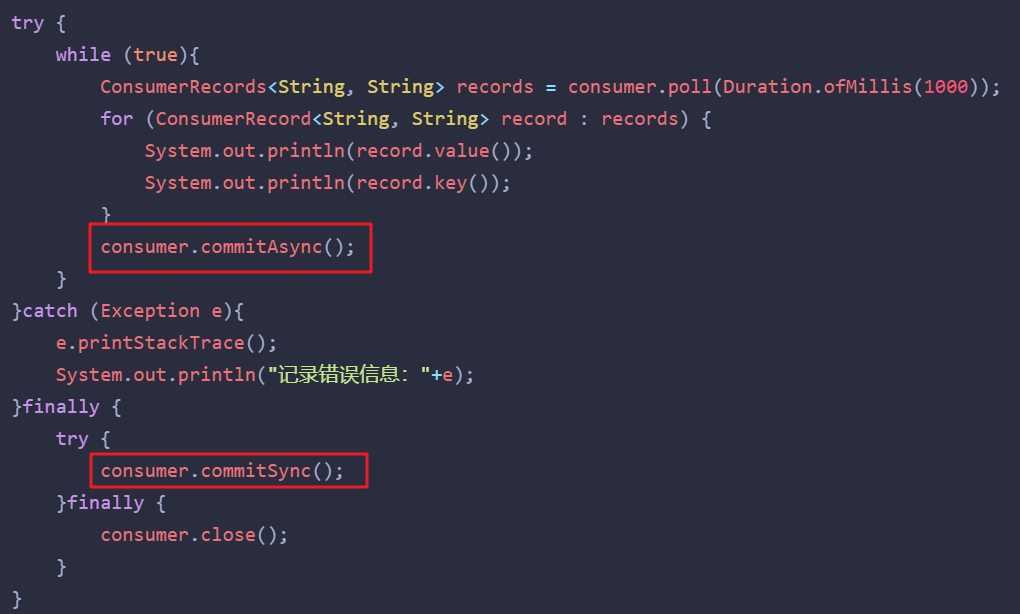

| 方式 | 优点 | 需要处理的边界 |
|---|---|---|
| commitSync | 等待提交结果，错误可显式处理 | 阻塞与延迟，失败时允许重复 |
| commitAsync | 减少提交等待 | 回调失败、提交顺序、不能盲目重试旧位移 |
| 组合 | 平时降低等待，在交接/关闭时确认安全位置 | 必须提交业务完成前缀，并处理分区所有权 |

**原图修正：** poll之后的position可能包含未处理记录，`finally { consumer.commitSync(); }`不带位移映射会提交当前读取位置。在业务中途异常时，这可能跳过失败记录。“有finally”与“同步提交”都不能证明安全。

学习用单线程、失败后停止当前消费者的示例：

~~~java
try (KafkaConsumer<String, Event> consumer = new KafkaConsumer<>(properties)) {
    consumer.subscribe(List.of("order.events"));
    while (running) {
        ConsumerRecords<String, Event> records = consumer.poll(Duration.ofMillis(500));
        Map<TopicPartition, OffsetAndMetadata> safe = new HashMap<>();
        try {
            for (TopicPartition partition : records.partitions()) {
                for (ConsumerRecord<String, Event> record : records.records(partition)) {
                    // 独立本地事务实际提交后才返回，服务内部做持久幂等。
                    eventService.applyIdempotently(record.value());
                    safe.put(partition, new OffsetAndMetadata(record.offset() + 1));
                }
            }
        } catch (RuntimeException businessFailure) {
            // 只提交本批次各分区连续已成功的部分。
            // 若提交失败，也允许恢复后重复；不继续poll跨过失败记录。
            if (!safe.isEmpty()) consumer.commitSync(safe);
            throw businessFailure;
        }
        if (!safe.isEmpty()) consumer.commitSync(safe);
    }
}
~~~

此片段省略运行生命周期、序列化器、RebalanceListener、提交失败日志等。它假定关闭自动提交，所有业务与Consumer调用由当前线程串行完成。业务失败后退出/重启，从已提交安全位置恢复。不能捕获异常后直接继续下一次poll，否则读取position可能已越过失败记录。若要继续运行，需要按所有权正确seek回未完成位置，或使用明确的重试/暂停策略。

**异步提交补充：** 回调失败时不要把旧offset不加判断地重新提交，后续较新提交可能已经成功。应用需要提交序列与安全位移管理。Rebalance和关闭时同步提交也只提交当前仍拥有分区的安全前缀，不能提交尚在后台执行的记录。

**多线程消费补充：** 按分区管理任务队列，所有者线程处理pause/resume与提交，工作线程只报告完成。102先完成而101未完成时，提交不能超过101。失去分区后处理在途任务的停止与业务幂等，防止旧消费者继续造成重复副作用。


## 23. Kafka重复消费与事务/EOS范围

**课件第29页，在线问答9：** 手动控制位移，并用唯一主键、业务标识或锁处理幂等。

常见重复来源：业务事务成功但位移提交失败、Rebalance时任务尚未完成、消费者重启、人工回退位移、生产者/Outbox重复发布、失败Topic重放。关闭自动提交并不能消除所有这些来源。

**外部数据库处理方案：** 沿用第8节的Inbox唯一键与业务更新同事务，事务提交后提交安全位移。若两者之间崩溃，再读到同一事件时确认业务已完成即可提交进度。

**为什么不直接用(topic, partition, offset)作所有业务去重键？** 这个组合标识一条Kafka日志记录，适合日志位置去重。但同一个业务事件被重发到新的offset，组合不同，仍会重复生效。稳定event_id表达业务身份，二者可按需要同时记录。

**补充Kafka事务处理：**

~~~text
beginTransaction
读取输入记录并生成Kafka输出记录
send输出记录
sendOffsetsToTransaction(安全位移, 当前消费组信息)
commitTransaction
失败则abortTransaction
~~~

通常还需启用事务生产者、合理的`transactional.id`管理，读取方根据需要使用`isolation.level=read_committed`。Kafka事务可让Kafka输出与消费组位移原子提交，并防止旧事务生产者继续写入。项目依赖与API版本需要匹配。

**范围修正：** 上述事务不包含普通外部数据库事务、HTTP调用、邮件或第三方支付。把数据库写完再`commitTransaction`仍有两个系统间的失败窗口。可以通过业务约束、Outbox/Inbox、受支持的集成设计或对账解决，不能直接宣称Kafka EOS覆盖全部外部业务。

**锁的边界：** 即便同一个业务ID被Redis锁串行处理，第二次拿锁仍会再次扣款。锁内仍要检查持久交易记录/状态，并且提交时序、租约和过期要正确。幂等应明确输入身份、业务状态、原子提交及记录生命周期。


## 24. Kafka顺序：同一业务key、单分区与处理串行

**课件第30～32页，在线问答10：** Kafka分区内有序，跨分区没有统一顺序。发送时指定partition或对同一业务设置相同key。

~~~java
// 同一订单的事件使用相同key，使用一致的分区策略。
ProducerRecord<String, Event> byKey =
    new ProducerRecord<>("order.events", orderId, event);

// 显式指定分区，示例分区号必须实际存在。
ProducerRecord<String, Event> explicit =
    new ProducerRecord<>("order.events", 0, orderId, event);
~~~

**修正：** 在线讲义“Kafka默认不保证消息顺序”应补充范围。Partition日志本身按offset有序，Topic所有分区合起来没有全局业务顺序。日志读取有序也不代表并发业务一定按相同次序完成。

| 场景 | 可能破坏的顺序 | 补充措施 |
|---|---|---|
| 一个订单事件分散到不同分区 | 分区间处理顺序 | 同一业务key稳定映射到同一分区 |
| 消费者将同分区记录投到普通线程池 | 业务完成顺序 | 按分区/业务key串行执行 |
| 失败事件进入独立Retry Topic，后续继续处理 | 业务状态先后 | 阻塞该key、业务版本校验或专门恢复协议 |
| 多个生产者并发发布同一业务事件链 | 业务发生顺序与写入顺序 | 源端版本/序号、业务事务顺序设计 |
| 增加Topic分区数 | key映射与旧新消息交错 | 迁移期间控制生产和消费切换 |
| 关闭生产者幂等，允许多请求在途并发生重试 | 某些配置下的重试写入顺序 | 核对幂等、in-flight与重试组合 |

**业务版本补充：** 订单事件附带version。消费者忽略已经应用的旧版本，对缺失版本定义等待、查询权威状态或补偿策略。若事件只是通知“发生了变化”，可以重新读取权威数据。若事件是不可交换的增量操作，不能简单跳过前序事件。

若需要整个Topic的日志全局顺序，单分区是一种办法，但限制吞吐和并行。业务通常只需要单订单、单会话、单账户范围内顺序，因此选择业务key分片更合理。单个热点key仍会集中于一个分区/处理序列，需要独立容量评估。

**面试回答：** 同key同分区、生产端排序/重试条件、消费端串行与失败恢复三者共同保证业务顺序。只设置key还不够。


## 25. Kafka集群复制：Leader、Follower与ISR

**课件第33～37页，在线问答11～12：** 多Broker集群与分区副本共同提供高可用。每个分区有leader与followers，leader故障后进行选举。

例如Topic有P0、P1、P2，每个分区3副本，可将不同分区的leader分散到A、B、C三个Broker。每个Broker同时保存多个不同分区的leader或follower副本，leader分布决定部分请求负载。

**ISR修正：** ISR是In-Sync Replicas集合，**包括leader和满足同步要求的followers**。课件将它概括成“同步复制的follower”过于简化。Followers一般从leader拉取日志，存在复制延迟。进入ISR表示满足协议的追赶要求，并不意味着每个时刻与leader逐字节完全相同。

~~~text
分区P0的副本：A(leader)、B、C
当前ISR：A、B
C因落后暂时不在ISR

acks=all、min ISR=2：
  确认要求结合A/B的复制状态
C追赶满足条件后可重新进入ISR
~~~

**补充日志位置：** Leader的log end offset描述其日志末端，high watermark反映按复制规则可供正常消费者读取的提交边界。使用事务时，read_committed还受到事务稳定位置等条件约束。不要把“leader刚写进日志”直接等同于所有消费者已经可读。

Kafka高可用需要每个关键分区具备合适副本数、ISR健康、leader可迁移、故障域分散，还需要集群元数据/控制面可用。仅说明“其余Broker还能提供服务”不能证明故障Broker负责的所有分区都能继续读写。

**控制面版本补充：** 旧教材可能采用ZooKeeper，现代Kafka可使用KRaft控制器管理元数据。Broker数据副本与控制器元数据多数派属于不同层次，不能混为一套复制组。课件主要讨论数据分区复制，未展开控制面配置。

副本恢复和新增副本会消耗网络与磁盘，Reassignment需控制速度并监控。副本都在同一机架或存储故障域，节点数量看似足够，也可能在同一次故障中全部失效。


## 26. ISR不足、Leader选举与可靠性取舍

**课件第36页配置图：** 副本数3、最小同步副本2。

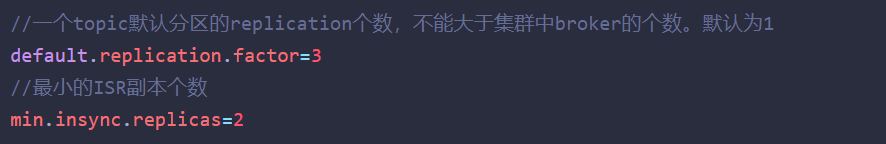

**配置位置修正：** `replication.factor=3`是Topic副本数的表达，不能只把它随意放进producer.properties就认为已改变现有Topic副本。Topic的创建/变更与Broker默认副本设置各有配置位置。`min.insync.replicas`也应确认Topic覆盖值与Broker有效默认值。

| 故障情形 | 常见处理逻辑 | 业务影响 |
|---|---|---|
| Leader A失效，ISR中B可用 | 按协议从可选ISR副本选新leader | 短时切换、生产/消费重试 |
| 有leader但ISR数量低于min ISR | acks=all写入不能满足要求 | 拒绝/失败写入，保留发布意图 |
| 没有可用的ISR候选 | 取决于恢复及选举策略 | 可能暂时不可用 |
| 允许不干净选举并选落后副本 | 可恢复部分服务 | 可能丢失已经确认的记录 |

**修正：** 课件“ISR都不行就只能从普通follower选”不是必然规则。是否允许非ISR副本当选取决于`unclean.leader.election.enable`等配置和版本机制。禁止不干净选举时，可能选择等待合适副本恢复，以保数据安全。新版本其他恢复选举功能也需核对文档，不能套用绝对判断。

学习配置意图：

~~~text
业务重视已确认数据的安全：
  分区副本跨故障域部署
  acks=all
  min.insync.replicas设置为允许的最低复制条件
  不随意允许落后副本接任
  ISR不足告警，生产者保留可恢复的待发送记录
~~~

“强行降低最小ISR”与“开启不干净选举”可能改善短时可用性，但改变了数据丢失风险。是否允许，需要实际业务SLA与事故处置授权，不能作为常规自动操作。

**监控补充：** Under-replicated partitions、Under-min-ISR partitions、Offline partitions、ISR变化、请求错误率、复制延迟、磁盘与网络，都比单看Broker进程在线更能说明容错条件。

三副本不意味着可随意同时重启两台。滚动维护前检查ISR与控制面健康，每一步等待复制恢复，避免多个不同故障叠加。


## 27. Kafka文件：Partition目录、Segment与稀疏索引

**课件第38～39、41页：** Topic数据存储在分区上，分区日志按Segment切分，包含`.log`、`.index`、`.timeindex`。

~~~text
日志目录/
  orders-0/
    00000000000000000000.log
    00000000000000000000.index
    00000000000000000000.timeindex
    00000000000000100000.log
    00000000000000100000.index
    00000000000000100000.timeindex
  orders-1/
    ...
~~~

示例文件名表达Segment的base offset，实际大小、文件列表和额外元数据文件随版本/配置不同。不能把文件名100000解释成“这个文件恰好有100000条记录”。

| 文件 | 常见职责 |
|---|---|
| .log | 保存消息记录批次及相应日志数据 |
| .index | 稀疏的offset到文件位置映射 |
| .timeindex | 按时间辅助定位offset |

**补充查找流程：** 根据目标offset定位可能包含它的Segment，在offset索引中找到不超过目标的近邻位置，再从对应日志位置向后读取定位记录。索引是稀疏结构，不是每条消息都有一条完整独立索引记录。

时间查找通常先用时间索引确定近邻offset，再定位日志记录。消息时间戳来源、时间索引与实际查找语义应核对Broker的时间戳配置，不要假定总是用户真实业务发生时间。

**分段的作用：** 持续向活动Segment追加，达到大小或时间条件后滚动。旧的非活动Segment可整段清理，降低维护超大单文件的成本，也便于索引、恢复和日志管理。

**补充边界：** Offset在一个分区内有顺序，受压缩、事务、删除等机制影响，消费者看到的可读记录不保证每个整数offset都存在。消费者按协议迭代返回记录，不能通过“offset差值”直接推算精确业务条数。

数据目录属于Broker管理的存储，不应直接编辑/删除Segment来处理积压。清理要通过受支持配置与运维流程，并考虑消费回放需求。


## 28. Kafka清理：保留时间、容量与Log Compaction

**课件第40～41页，在线问答13：** 根据保留时间和日志大小清理。示例为`log.retention.hours=168`，即7天。图中的`#log.retention.bytes=1073741824`带注释，只是展示配置位置，不能当成已启用1GiB限额。

| 课程/补充参数 | 作用 | 必须明确的范围 |
|---|---|---|
| log.retention.hours / retention.ms | 按时间保留 | Broker默认与Topic覆盖值、时间戳规则 |
| log.retention.bytes / retention.bytes | 按大小保留 | 通常按分区计算，并非全Topic共用一个上限 |
| log.segment.bytes / segment.bytes | 控制Segment滚动大小 | 影响清理粒度与文件数量 |
| cleanup.policy=delete | 按时间/大小删除旧Segment | 消费进度通常不阻止删除 |
| cleanup.policy=compact | 按key整理较旧记录 | 保留状态类日志语义，有异步清理与tombstone规则 |

**修正：** Kafka不会因为所有消费者已经消费并提交位移，就立即删除那些记录。消费位移与日志保留策略独立。同样，落后消费者不能凭“尚未消费”阻止保留期清理。

清理通常按Segment和后台周期进行，活动Segment等条件会影响执行。168小时不是每条消息在精确到期毫秒立刻删除的承诺。消息时间戳、文件滚动与检查周期也会影响实际边界。

**容量示例：** 若一个Topic有3个分区，每分区retention.bytes约1GiB，逻辑数据保留量可近似按3GiB估算，还受Segment粒度影响。3副本下物理集群磁盘需求进一步扩大，并包含索引、在途、恢复和余量。不能把1GiB误当整个Topic所有副本的总占用。

**补充Compaction：** 适合保留每个key近期状态的变更日志，例如账户最新资料。它异步整理被后续同key记录覆盖的旧值，消费者仍可能看到旧值。带null value的tombstone表示删除意图，保留与清理规则影响落后消费者能否重建正确状态。无key、纯追加事件及不同业务保留目的需另外分析。`delete,compact`可组合，但含义需按配置解释。

**位移越界：** 消费者提交位置已经早于最早保留数据时，无法从原offset直接恢复。`auto.offset.reset`可以定义某些无有效位置场景的行为，但自动从earliest/latest开始可能造成缺口或重复。需要告警、业务补数、备份/上游重放或重新构建派生数据。

容量规划根据输入字节率、保留时间、副本数、压缩率、回放需求与故障恢复余量估算，不能只按“默认7天”决定业务可恢复窗口。


## 29. Kafka高性能之一：分区并行与顺序追加

**课件第42、45页，在线问答14：** 分区、顺序读写、页缓存、零拷贝、压缩和批量是六个主要方向。

**分区并行：** 不同分区的leader可以分布于不同Broker，生产和消费可以并行。单组消费者的并行能力也与分区数有关。分区能扩展处理能力，但课件“不受限处理更多数据”应修正为“受集群资源、分区管理、热点和业务约束影响”。

| 增加分区可能获得什么 | 同时增加什么成本 |
|---|---|
| 更多Broker分担数据读写 | 文件、索引、元数据与复制管理 |
| 更多组内消费者并行 | Rebalance、任务分配与业务连接 |
| 更分散的业务key | 分区迁移、热点及key映射变化 |
| 更大的整体吞吐 | leader故障恢复和控制面负担 |

**顺序追加：** 向分区日志末尾追加批次，避免频繁随机修改。磁盘顺序访问通常比随机访问更适合大吞吐。消费者顺着offset读取也能较好使用预读和缓存。

**补充边界：** 多个分区同时写、多消费组读不同历史位置、压缩清理与副本恢复，都可能增加IO竞争。SSD、操作系统、文件系统、冷热数据与网络配置会改变瓶颈。不能仅凭“顺序写”就给出没有实测的吞吐结论。

**热点分析：** 单个业务key落在单分区，其他分区空闲也无法直接提升这个key的串行业务吞吐。可以优化业务处理或调整业务粒度，但不能无条件拆key而破坏余额/订单的顺序与原子性。

性能验证应同时观察吞吐、p95/p99延迟、错误率、消费者lag、CPU、磁盘与网络，以及副本健康。比较方案时固定消息大小、压缩、acks、副本数、并发和硬件条件。


## 30. 页缓存与零拷贝：减少哪些开销

**课件第42～44页：** 页缓存将部分磁盘访问转化为内存访问。零拷贝减少数据拷贝和上下文切换，课件用传统路径与优化路径示意。

**页缓存补充：** Kafka利用操作系统Page Cache缓存文件页。近期写入和读取的数据可能直接来自缓存，并可借助顺序访问预读。缓存由操作系统统一管理，Kafka进程堆内存不是保存全部消息的唯一位置。

内存压力、冷回放、日志清理和副本同步可能使命中率降低，触发真实磁盘读写。文件写入页缓存成功也不能直接说“此刻物理磁盘已可靠落盘”。耐久性要结合Kafka复制、确认与恢复条件。

传统文件发送的简化路径：

~~~text
磁盘数据进入内核页缓存
复制到用户态应用缓冲
复制到内核Socket相关缓冲
发送到网卡
~~~

适用条件下的优化路径：

~~~text
文件页缓存的数据通过sendfile/类似机制传给网络发送路径
避免把整批数据复制进Kafka用户态后再复制回内核
部分硬件/内核路径可进一步减少复制
~~~

**修正：** 零拷贝不是从磁盘到网卡完全没有任何数据搬运，也不是零CPU工作。它重点减少特定用户态与内核态拷贝/切换。具体次数取决于OS、内核、网络栈和硬件，不能把课件示意图当成每个环境完全固定的次数表。

Kafka常通过文件传输接口使用适合的路径。TLS加密、消息转换或格式条件可能使相关数据需要应用层处理，影响传统零拷贝可用条件。不能断言所有Kafka网络流量、包括生产者写入路径都采用完全相同的零拷贝机制。

**面试回答：** 页缓存降低重复磁盘读取，零拷贝降低文件发送路径的重复数据复制与切换。两者与顺序读写、批量共同支持吞吐，但不能单独证明业务端低延迟或可靠性。


## 31. 压缩与批量：吞吐、延迟和CPU的平衡

**课件第42、45页，在线问答14：** 压缩减少磁盘和网络IO，分批发送减少网络请求开销。

**补充批量：** Producer通常按目标分区组织批次。多个记录批量发送可减少请求、协议头和系统调用开销。不是任意Topic所有消息随意打成一个不分区的业务大事务。

| 参数/机制 | 调整方向 | 代价与限制 |
|---|---|---|
| batch.size | 更大的批次容量有利吞吐 | 需要足够同分区流量，消耗缓冲内存 |
| linger.ms | 允许等待以聚合更多记录 | 增加部分记录等待时间，默认值跨版本变化 |
| compression.type | gzip、snappy、lz4、zstd等按版本选择 | 压缩率、CPU和延迟不同，兼容性需确认 |
| buffer.memory | 影响Producer可缓冲的规模 | 不是无限队列，满时可能阻塞/失败 |
| max.request.size | 限制请求大小 | 须与Broker/Topic及消费端限制兼容 |
| fetch.min.bytes / fetch.max.wait.ms | 消费端聚合拉取 | 吞吐与低流量等待时间的权衡 |

学习用配置，仅展示含义，不作为固定推荐值：

~~~java
properties.put(ProducerConfig.BATCH_SIZE_CONFIG, 32 * 1024);
properties.put(ProducerConfig.LINGER_MS_CONFIG, 5);
properties.put(ProducerConfig.COMPRESSION_TYPE_CONFIG, "lz4");
~~~

上面32KiB和5ms是练习值。实际根据消息大小、分区数、流量和p99目标测试。低流量下不一定填满批次，分区太多还会分散每分区的聚合机会。

压缩通常以记录批次为单位更高效，适合可压缩的载荷。已经压缩的图片/密文再压缩收益可能较低。发送、Broker处理和消费者解压的CPU都需要观测，不能只看网络字节下降。

**可靠性边界：** 批量/压缩优化与acks、幂等和副本保证配合使用。为了提高数字而改成acks=0会改变业务可靠性条件，性能比较必须注明。业务端批量入库也要管理事务大小、锁、部分失败和位移提交，不能提交整个poll却只完成一部分业务。


## 32. 综合案例：MySQL变更后同步Redis或ES

**课件第4页、在线问答1：** 将MQ用于MySQL与Redis/ES间同步。以下是补充设计，不代表已运行课程工程。

设计目标：数据库保存权威状态，派生系统在允许时间内收敛，故障后可定位和修复。

~~~text
事务T1：更新DB对象、增加version、写同一事务Outbox
发布任务：按event_id发送对象变更事件并取得确认
消费者：校验消息，按对象ID应用版本或重新读权威状态
结果处理：成功后确认/提交安全位移，失败分类重试
补偿任务：检查Outbox、死信、目标系统版本与业务差异
~~~

事件可包含event_id、entity_id、event_type、version、occurred_at与载荷。含义需要定义：事件携带完整快照、携带增量，还是只提示“源数据已变更”。三者不能用相同去重/乱序处理方式。

| 问题 | 处理方向 |
|---|---|
| DB提交后应用崩溃，尚未发消息 | 同事务Outbox/受控CDC保留发送意图 |
| 消息重发 | 稳定event_id、业务幂等或目标版本规则 |
| v12先到、v11后到 | 目标端原子版本检查，禁止旧版本覆盖新状态 |
| Redis/ES长时间不可用 | 有界重试、失败归档、告警和补偿 |
| 缓存被读请求回填旧值 | 协调缓存回填、失效和版本策略 |
| 删除事件或缓存键过期 | 定义删除版本/tombstone与回填语义 |
| 消费位移已过保留边界 | 从源DB重建或其他受支持补数 |

**版本检查补充：** “先读目标version再写新值”若分两步并发执行仍有竞争，应使用目标系统支持的原子条件更新、CAS/Lua等合适机制。跨Redis和数据库的步骤也不是普通本地事务，需明确失败窗口和恢复方式。删除缓存后旧读请求再次回填的竞争，不能仅靠消费幂等解决。

**一致性边界：** MQ保证事件传播流程，不意味着读请求立即读到新缓存。接口对强一致读取有要求时，可以读权威数据库或采用经过设计的读策略。声明最终一致时，还要给出允许延迟、告警阈值、补偿和业务降级措施。

**顺序选择：** Kafka按entity_id作为key便于同对象分区顺序。RabbitMQ可按业务key设计队列分片与串行处理。无论选择哪种，目标版本与幂等约束仍能应对重复、重放与处理并发。

**项目口述模板：** 真实说明业务允许的延迟、事件生成方式、确认策略、消费者处理和对账，再给实际验证数据。没有做过的细节可以表述为理解/设计方案，不要照抄讲义“我们项目使用”的措辞。


## 33. 常见故障：从业务结果反查消息链路

以下是基于本篇机制的排障补充，未在真实环境执行。

| 现象 | 先检查什么 | 原因候选 |
|---|---|---|
| Rabbit发布Confirm ACK，队列没收到 | event_id、Return、routing key、绑定和目标队列 | 未路由却获ACK、声明错误、消息很快被消费 |
| Rabbit Ready不高但业务没完成 | Unacked、监听器返回时点、业务事务与失败归档 | 提前ACK、把任务丢线程池、失败消息归档丢失 |
| 一条Rabbit消息反复出现 | event_id、本地Retry、requeue、x-death和失败原因 | 无限重入队、毒消息、失败归档循环 |
| Kafka发送超时但消费者看到了记录 | producer回调、acks/超时和event_id | 写入成功但回应未知，重试造成新记录 |
| Kafka lag很低但数据库少数据 | 提交位移与真实业务完成位置 | 位移提前提交、错误finally或异步任务尚未完成 |
| Kafka副本数是3仍然写入失败 | 当前ISR、min ISR、leader、鉴权和磁盘 | 同步副本不足或其他发布错误 |
| Kafka同key仍然业务乱序 | 分区、producer数量、线程池、重试Topic及业务版本 | 业务完成并发、跨流重试或扩分区 |
| 老消息读不到 | earliest offset、保留参数与cleanup policy | 已清理或压缩，提交位移越界 |

**定位顺序：**

1. 用业务ID/event_id确认预期业务是否成功，以数据库/权威系统为准。
2. 查事件是否生成、Outbox是否提交以及发送尝试与确认结果。
3. 查具体队列或Topic/Partition/Offset，避免仅看整体平均指标。
4. 查消费者日志、幂等记录、业务事务、ACK/位移提交和失败归档。
5. 明确最小修复范围，先修正确性，再在保持幂等的条件下重放。

**lag补充：** Kafka lag是消费进度相对日志边界的指标，具体监控定义可能取已提交位置或当前位置。它不能直接证明业务数据库已完成。偏移量差也不一定等于精确待处理业务条数，需结合日志记录、事务和压缩等条件。

**恢复纪律：** 不通过清空队列、直接改进度或关闭可靠性参数制造“指标恢复”。若需要回退位移、迁移队列、重放死信，先确认身份与范围、业务幂等、保留窗口和容量，并保留审计记录。学习笔记中的排障建议不构成实际生产操作授权。


## 34. 高频面试自测与简答

以下答法围绕机制，可根据真实项目补充版本、场景与验证结果。

**1. RabbitMQ如何尽量保证不丢消息？** 发布端Confirm/Return和可恢复发送意图，Broker合适的持久化/副本，消费端业务提交后ACK，失败有界重试与可审计归档，同时做幂等和对账。明确正常故障范围。

**2. Confirm ACK与Consumer ACK有什么区别？** 前者对应发布接管结果，后者对应消费投递的处理确认。前者不证明消费者业务完成。Return再覆盖未路由情形。

**3. Spring AUTO是不是拿到消息就删？** AUTO由容器根据监听器结果确认，协议不等待消费确认的语义更接近NONE。实际业务必须在正常返回前完成，事务与异步执行时点需核对。

**4. 消费者已经提交数据库，ACK失败怎么办？** 允许消息重投，通过稳定业务事件ID和数据库幂等判断已完成，再确认。强行省掉重投会引入漏处理风险。

**5. 锁能保证重复消息不再生效吗？** 锁提供并发互斥，后续重复仍能再拿锁。持久业务状态/唯一流水与业务写入同事务负责长期幂等，锁只是可能的辅助。

**6. 死信与延迟队列如何联系？** 无消费者等待队列里的消息过期后，经配置的DLX路由到业务处理队列。也可用延迟插件。拒绝、TTL、长度/投递限制等具体死信条件依队列和策略分析。

**7. 消息TTL能精准关单吗？** TTL路由有队头阻塞、周期与负载等边界。消费者检查实际expire_at和状态，处理支付竞争，扫描任务兜底。

**8. 百万积压如何解决？** 先查Ready/Unacked、消息年龄与下游瓶颈，估算μ-λ，优化/扩容可并行消费、合理分片和流控。存储扩容提供缓冲，不能解决持续吞吐缺口。

**9. RabbitMQ三节点集群一定高可用吗？** 还需队列消息副本、成员与故障域、客户端恢复和资源条件。普通集群不自动复制每条消息。Quorum需要多数派。

**10. Kafka acks=all是否所有副本都写完？** 它依据ISR确认条件，结合副本数、min ISR和选举策略解释。所有配置副本并不一定都在ISR中。

**11. ISR是什么？** 包括leader及满足同步条件的followers。Follower通常拉取复制，可能有延迟。ISR用于复制确认和安全候选，不是另一个固定同步传输协议类别。

**12. Kafka消费业务成功后提交多少？** 各分区连续已完成记录的下一位置。100成功、101失败，即使102先成功也不能提交103，应保留101作为恢复起点。

**13. 手动commit是否防止重复？** 提供提交时点控制，业务成功到commit成功之间仍有故障窗口。重复由持久幂等处理。

**14. finally同步提交为什么可能丢业务？** 无参数commitSync提交当前读取position，poll已经越过未处理记录。退出时只能提交安全前缀，失败记录恢复时仍要读取。

**15. Kafka怎样保证订单事件顺序？** 同订单使用稳定key/分区策略，消费端按相应范围串行，生产重试、扩分区与失败恢复需保持语义。业务版本处理重放和缺口。

**16. Kafka事务能保证数据库扣款恰好一次吗？** 普通Kafka事务主要覆盖Kafka输出和消费位移。外部数据库/支付仍需事务、流水约束、幂等与对账设计。

**17. 消费完的Kafka日志是否删除？** 不因某组消费结束而立即删除，按retention/cleanup策略处理。慢消费者也可能被保留策略越过。

**18. Kafka为什么快？** 分区并行、顺序追加、页缓存、适用路径上的零拷贝、批量和压缩共同减少IO和请求开销。还需说明吞吐/延迟/CPU与可靠性条件。

**19. Lazy Queue与Quorum有何区别？** 前者是旧版本经典队列的资源管理模式，后者是Raft复制的队列类型。关注维度不同，并且旧lazy与镜像配置有版本变化。

**20. 如何证明“不丢、幂等、有序”？** 做故障注入和业务结果核对，记录事件ID、业务流水与安全进度，验证崩溃窗口、重试、Rebalance及副本故障。不能只看MQ已发送条数或消费者lag。


## 35. 学习练习：故障窗口与验收标准

以下是可自行在隔离学习环境执行的实验方案，**本轮未执行**。无需直接操作生产队列或业务系统。

### 练习A：路由失败与Confirm

给学习用Exchange发布一个没有对应绑定的routing key，开启mandatory、Return和Confirm。观察两类回调如何关联同一event_id。

**验收：** 不因单独Confirm ACK把未路由事件标成已正确送达队列。错误记录可查询，修复绑定后重试保留原event_id。

### 练习B：DB提交后、ACK前崩溃

用唯一支付事件更新学习用交易流水，在业务提交后、ACK前模拟消费者退出，重启后再次消费。

**验收：** 同一业务流水只生效一次，幂等记录与业务状态同事务，重复消息可安全确认。并发两个相同事件时也不出现重复余额增加。

### 练习C：短TTL排在长TTL后

在隔离等待队列中先发送长TTL，再发送短TTL，分别记录业务due_at、入队时间和进入实际处理队列的时间。

**验收：** 根据实际版本观测延迟，不把TTL当成精准定时承诺。业务使用当前状态/截止时间判断，旧事件不会关闭已支付订单。

### 练习D：Kafka poll中途业务失败

本次poll得到100、101、102，只使100成功，101发生异常。对比错误的无参数finally commit和安全位移映射。

**验收：** 正确方案不会跨过101，恢复后允许100重复但不重复生效，101/102仍可完成。不以lag降低代替数据库结果验证。

### 练习E：ISR从3降至1

使用隔离三副本Topic、min ISR=2、acks=all，逐步模拟副本不可用，观察写入与错误记录。

**验收：** ISR不足时失败事件留在可恢复发布记录，应用不谎报完成。恢复后补发，重复不造成重复业务。注意并发维护和控制面条件。

### 练习F：乱序与清理

同业务对象发布v11/v12，模拟多线程使v12先完成，再用学习用短保留Topic模拟消费者落后。

**验收：** v11不覆盖v12，缺口有明确规则。位移越界时告警并采用受控重建/补数，不默默跳到latest后宣称业务完整。

**建议记录表：** 版本、消息大小、分区/副本/队列类型、event_id、故障位置、业务结果、确认/提交位置、重复次数、恢复时间、未完成记录。性能练习另记录acks、压缩、批量、p95/p99和资源利用率，避免比较条件不同的结果。


## 36. 来源覆盖、版本说明与重点勘误

### 课件覆盖

| PPT页码 | 实际主题 | 本笔记位置 |
|---|---|---|
| 1～3 | 封面、主题路线、RabbitMQ导航 | 导读、1 |
| 4～8 | 场景、Confirm/Return、持久化、消费确认与Retry | 1～7、17 |
| 9 | 重复消费与业务幂等 | 2、8 |
| 10～15 | 死信、TTL、延迟插件与场景 | 9～12 |
| 16～18 | 百万积压与旧lazy队列 | 13～14 |
| 19～23 | 普通集群、镜像、仲裁队列 | 15～17 |
| 24～29 | Kafka发送、acks、消费组、位移与重复 | 18～23 |
| 30～32 | Kafka顺序与key/partition | 24 |
| 33～37 | Broker集群、复制、ISR | 25～26 |
| 38～41 | Segment、索引、日志清理 | 27～28 |
| 42～45 | 分区、顺序IO、缓存、零拷贝、压缩、批量 | 29～31 |
| 46 | 空白 | 无需补写课程内容 |

在线讲义14组正文问答分别对应：1可靠性、2～3幂等、4延迟/死信、5积压、6～7Rabbit高可用、8Kafka可靠性、9重复、10顺序、11～12复制/ISR、13清理、14性能，全部已读取。

视频11节已核对标题：课程介绍、Rabbit不丢失、Rabbit重复、死信/延迟、积压、Rabbit高可用、Kafka不丢失、Kafka顺序、Kafka高可用、Kafka清理、Kafka性能。未观看或转写，因此不将视频细节视为已核验资料。

### 重点勘误与补充索引

| 原资料容易产生的理解 | 本笔记修正 |
|---|---|
| Confirm等于业务完成 | 发布确认、路由Return、消费ACK分环节，见3 |
| 三重持久化等于任何故障都不丢 | 结合Confirm、副本、存储恢复和消费事务，见5 |
| Spring AUTO就是一投递就确认 | 容器AUTO与协议autoAck区分，见6 |
| 开启Retry就自动归档异常队列 | Recoverer、异常Exchange/Queue及可靠发布需配置，见7 |
| 业务ID先查后写或一把锁足够 | 唯一约束、持久状态与同事务，见8 |
| 延迟插件是死信插件 | DLX职责与x-delayed-message机制不同，见9、11 |
| 消息TTL精确保证任意延迟 | 队头阻塞、检查机制与业务状态验证，见10～12 |
| lazy是所有新版本通用调优 | 3.12起旧lazy模式语义变化，见14 |
| 普通集群节点宕机一定永久丢消息 | 区分暂时不可用与磁盘永久损失，见15 |
| 镜像队列可直接用在所有新版 | 经典镜像在4.0移除，见15 |
| 调用quorum就无条件高可用 | 实际副本、多数派与故障域条件，见16 |
| Kafka异步发送本身防丢 | 结果处理、持久意图、重试与确认条件，见19 |
| 发送失败后继续读取metadata | 失败回调应返回，metadata可能为null，见19 |
| acks=1永远是默认，all是全部副本 | 默认值随版本，all依据ISR，见20 |
| 提交poll位置就是提交业务成功 | 提交分区连续成功前缀的下一位置，见21～22 |
| finally无参数同步commit最安全 | 可能跨过失败业务，见22 |
| 同key就是整个业务必然有序 | 生产端、映射、消费并发与失败恢复一起分析，见24 |
| ISR只包括follower且完全同步 | 包括leader，follower拉取且满足追赶条件，见25 |
| ISR全失败必然选任意副本 | 由选举策略和版本条件决定，见26 |
| 大小限额是全Topic总量 | 通常按分区，消费进度不控制删除，见28 |
| 分区无限扩容、零拷贝完全无复制 | 资源与协议约束、适用传输路径，见29～30 |
| Kafka EOS覆盖普通DB和支付 | 指定Kafka事务范围，外部业务另做幂等，见23 |

Outbox、Inbox、订单支付竞争、消费安全前缀、Kafka事务、Compaction、控制面区别及故障验收均为明确标注的补充，用于把课程机制连接成完整业务流程。未声称这些细节都出自原PPT，也未逐项联网核验当前最新实现。

### 来源

- 网盘分享：[2023版Java面试教程](https://pan.baidu.com/s/1NQZDW-9_VCnEUXcXp_G-bA?pwd=9987)，提取码9987。
- 主课件：`06-消息中间件篇/PPT/06-消息中间件篇.pptx`，46页。
- 在线讲义入口：[面试专题](https://heuqqdmbyk.feishu.cn/wiki/RymLwLLWfieibHkjf17cKhY4nlf)。
- 实际正文：[消息中间件篇](https://heuqqdmbyk.feishu.cn/wiki/J74owY9Wri7gApkfIDWcTQ6anle)。

本篇仅生成学习笔记。配置与代码未执行，视频未观看，未安装插件、连接MQ/数据库、导入SQL、发送通知或压测。00～05已有笔记保持原内容。
